In [ ]:
# SETUP MANDIRI: menyiapkan folder, kode src/, dan dataset (SEED 1083) bila sesi baru
import os, sys, subprocess
ROOT = "/content/simuteh-2330511083"
for d in ["data/sintetis", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
FILES = {'src/utils_cv.py': '"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""\nimport cv2\nimport numpy as np\nimport matplotlib.pyplot as plt\n\n\ndef baca(path):\n    """Membaca citra dan langsung memberi pesan jelas bila gagal."""\n    img = cv2.imread(path)\n    if img is None:\n        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")\n    return img\n\n\ndef tampil(daftar, judul, baris=1, ukuran=(14, 4)):\n    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""\n    kolom = int(np.ceil(len(daftar) / baris))\n    plt.figure(figsize=ukuran)\n    for i, (im, jd) in enumerate(zip(daftar, judul)):\n        plt.subplot(baris, kolom, i + 1)\n        if im.ndim == 3:\n            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))\n        else:\n            plt.imshow(im, cmap="gray", vmin=0, vmax=255)\n        plt.title(jd)\n        plt.axis("off")\n    plt.tight_layout()\n\n\ndef kontras_bercak(kanal, mask_daun, mask_bercak):\n    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat."""\n    k = kanal.astype(np.float64)\n    sehat = (mask_daun > 0) & (mask_bercak == 0)\n    bercak = mask_bercak > 0\n    if bercak.sum() == 0:\n        return float("nan")\n    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)\n\n\ndef statistik(gray):\n    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""\n    return {"rerata": round(float(gray.mean()), 1),\n            "simpangan_baku": round(float(gray.std()), 1),\n            "min": int(gray.min()), "maks": int(gray.max()),\n            "persen_gelap": round(100 * float((gray < 50).mean()), 1),\n            "persen_terang": round(100 * float((gray > 205).mean()), 1)}', 'src/buat_dataset_sintetis.py': '"""\nbuat_dataset_sintetis.py\nMembangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.\n"""\nimport os\nimport csv\nimport cv2\nimport numpy as np\n\nSEED = 1083          # 4 digit terakhir NIM 2330511083\nN_PER_KELAS = 20\nH, W = 480, 640\nKELAS = ["sehat", "ringan", "berat"]\nKONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]\nOUT = os.path.join("data", "sintetis")\nrng = np.random.default_rng(SEED)\n\n\ndef gambar_daun(img, mask):\n    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""\n    cx = int(rng.integers(260, 380))\n    cy = int(rng.integers(200, 280))\n    ax = int(rng.integers(190, 240))\n    ay = int(rng.integers(95, 125))\n    sudut = float(rng.uniform(-25, 25))\n    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),\n                      rng.integers(45, 75)])  # BGR\n    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)\n    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)\n    # tulang daun utama dan cabang\n    t = np.deg2rad(sudut)\n    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))\n    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))\n    tulang = (hijau * 1.35).clip(0, 255).tolist()\n    cv2.line(img, p1, p2, tulang, 3)\n    for k in np.linspace(-0.7, 0.7, 6):\n        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)\n        for arah in (-1, 1):\n            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)\n            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)\n            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)\n    return mask\n\n\ndef gambar_bercak(img, mask_daun, mask_bercak, kelas):\n    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""\n    if kelas == "sehat":\n        return\n    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))\n    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)\n    ys, xs = np.where(mask_daun > 0)\n    for _ in range(n):\n        i = int(rng.integers(0, len(xs)))\n        r = int(rng.integers(r_min, r_maks + 1))\n        pusat = (int(xs[i]), int(ys[i]))\n        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),\n                 int(rng.integers(185, 210))]  # BGR pucat\n        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)  # tepi cokelat\n        cv2.circle(img, pusat, r, warna, -1)\n        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)\n    mask_bercak &= mask_daun  # bercak hanya di daun\n\n\ndef ganggu_cahaya(img, kondisi):\n    """Mensimulasikan kondisi pemotretan di lapangan."""\n    f = img.astype(np.float32)\n    if kondisi == "gelap":\n        f = 255 * (f / 255) ** 2.0\n    elif kondisi == "terang":\n        f = 255 * (f / 255) ** 0.45\n    elif kondisi == "kontras_rendah":\n        f = 0.35 * f + 95\n    elif kondisi == "bayangan":\n        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)  # separuh teduh\n        f = f * gx[None, :, None]\n    sigma = float(rng.uniform(6, 14))\n    f = f + rng.normal(0, sigma, f.shape)  # derau sensor\n    return np.clip(f, 0, 255).astype(np.uint8)\n\n\ndef main():\n    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:\n        os.makedirs(os.path.join(OUT, sub), exist_ok=True)\n    baris = []\n    nomor = 0\n    for kelas in KELAS:\n        for j in range(N_PER_KELAS):\n            nomor += 1\n            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),\n                              rng.integers(185, 215)])  # nampan anyaman\n            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)\n            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))\n            m_daun = np.zeros((H, W), np.uint8)\n            m_bercak = np.zeros((H, W), np.uint8)\n            gambar_daun(img, m_daun)\n            gambar_bercak(img, m_daun, m_bercak, kelas)\n            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)\n            kondisi = KONDISI[j % len(KONDISI)]\n            citra = ganggu_cahaya(bersih, kondisi)\n            nama = f"teh_{nomor:03d}.png"\n            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)\n            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)\n            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)\n            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)\n            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)\n            baris.append([nama, kelas, kondisi, round(persen, 2)])\n    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:\n        w = csv.writer(f)\n        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])\n        w.writerows(baris)\n    print(f"Selesai: {nomor} citra tersimpan di {OUT}")\n\n\nif __name__ == "__main__":\n    main()', 'src/praproses.py': '"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""\nimport json\nimport cv2\nimport numpy as np\n\nPARAM_BAWAAN = {\n    "lebar": 640,        # sampling: lebar citra kerja (piksel)\n    "gamma": 1.0,        # < 1 mencerahkan, > 1 menggelapkan\n    "clahe_clip": 2.0,   # 0 berarti CLAHE tidak dipakai\n    "clahe_tile": 8,\n    "penapis": "median", # "none", "rerata", "gaussian", "median"\n    "kernel": 3,\n    "sigma": 1.0,\n    "tajam_k": 0.0,      # 0 berarti tanpa penajaman\n}\n\ndef praproses(img_bgr, p=None):\n    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""\n    p = {**PARAM_BAWAAN, **(p or {})}\n\n    # 1. Ubah ukuran: lebar = p["lebar"], rasio aspek tetap, INTER_AREA\n    h, w = img_bgr.shape[:2]\n    tinggi = int(round(h * p["lebar"] / w))\n    img = cv2.resize(img_bgr, (p["lebar"], tinggi), interpolation=cv2.INTER_AREA)\n\n    # 2. Koreksi gamma lewat tabel LUT (hanya bila gamma != 1)\n    if p["gamma"] != 1:\n        lut = np.array([255 * (i / 255) ** p["gamma"] for i in range(256)])\n        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))\n\n    # 3. CLAHE hanya pada kanal V (HSV), lalu kembali ke BGR\n    if p["clahe_clip"] > 0:\n        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],\n                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))\n        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)\n        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])\n        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)\n\n    # 4. Redam derau (ukuran kernel harus ganjil)\n    k = int(p["kernel"])\n    if p["penapis"] == "rerata":\n        img = cv2.blur(img, (k, k))\n    elif p["penapis"] == "gaussian":\n        img = cv2.GaussianBlur(img, (k, k), p["sigma"])\n    elif p["penapis"] == "median":\n        img = cv2.medianBlur(img, k)\n    # "none": tidak melakukan apa-apa\n\n    # 5. Unsharp masking: citra + k * (citra - blur)\n    if p["tajam_k"] > 0:\n        blur = cv2.GaussianBlur(img, (5, 5), 1.0)\n        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)\n\n    return img\n\ndef simpan_param(p, path="../hasil/param_praproses.json"):\n    with open(path, "w") as f:\n        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)'}
for p, t in FILES.items():
    if not os.path.exists(f"{ROOT}/{p}"):
        open(f"{ROOT}/{p}", "w").write(t)
os.chdir(ROOT)
if not os.path.exists("data/sintetis/label.csv"):
    print(subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"], capture_output=True, text=True).stdout)
os.chdir(f"{ROOT}/notebook")


In [138]:
# === B5 ===
%cd /content/simuteh-2330511083/notebook
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

/content/simuteh-2330511083/notebook


In [139]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,        # sampling: lebar citra kerja (piksel)
    "gamma": 1.0,        # < 1 mencerahkan, > 1 menggelapkan
    "clahe_clip": 2.0,   # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 8,
    "penapis": "median", # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,      # 0 berarti tanpa penajaman
}

def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}

    # 1. Ubah ukuran: lebar = p["lebar"], rasio aspek tetap, INTER_AREA
    h, w = img_bgr.shape[:2]
    tinggi = int(round(h * p["lebar"] / w))
    img = cv2.resize(img_bgr, (p["lebar"], tinggi), interpolation=cv2.INTER_AREA)

    # 2. Koreksi gamma lewat tabel LUT (hanya bila gamma != 1)
    if p["gamma"] != 1:
        lut = np.array([255 * (i / 255) ** p["gamma"] for i in range(256)])
        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))

    # 3. CLAHE hanya pada kanal V (HSV), lalu kembali ke BGR
    if p["clahe_clip"] > 0:
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],
                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # 4. Redam derau (ukuran kernel harus ganjil)
    k = int(p["kernel"])
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)
    # "none": tidak melakukan apa-apa

    # 5. Unsharp masking: citra + k * (citra - blur)
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)

    return img

def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Overwriting ../src/praproses.py


In [140]:
import importlib, praproses
importlib.reload(praproses)
from praproses import praproses as pp, simpan_param
img = baca("../data/sintetis/citra/teh_045.png")
out = pp(img, {"penapis": "median", "kernel": 5})
print(out.shape, out.dtype)   # harus (480, 640, 3) uint8

(480, 640, 3) uint8


In [141]:
KANAL = 2   # R (kanal terbaik Bagian 2)
label = pd.read_csv("../data/sintetis/label.csv")
berbercak = label[label.kelas != "sehat"]

konfig = {
    "A: CLAHE2 + median5": {"clahe_clip": 2.0, "penapis": "median", "kernel": 5},
    "B: CLAHE1 + median5": {"clahe_clip": 1.0, "penapis": "median", "kernel": 5},
    "C: tanpa CLAHE + median5": {"clahe_clip": 0, "penapis": "median", "kernel": 5},
}
ringkas = {}
for nk, prm in konfig.items():
    baris = []
    for _, d in berbercak.iterrows():
        im = baca(f"../data/sintetis/citra/{d.nama_file}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
        o = pp(im, prm)
        baris.append([d.kondisi_cahaya,
                      kontras_bercak(im[:, :, KANAL], m_d, m_b),
                      kontras_bercak(o[:, :, KANAL], m_d, m_b)])
    ev = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
    t = ev.groupby("kondisi").mean().round(2)
    t["perubahan_%"] = ((t.KB_sesudah / t.KB_sebelum - 1) * 100).round(1)
    ringkas[nk] = t
    print("\n", nk); print(t)


 A: CLAHE2 + median5
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
bayangan              5.05        8.86         75.4
gelap                 9.92       18.83         89.8
kontras_rendah        3.72        5.01         34.7
normal                8.93       11.83         32.5
terang                6.54        6.12         -6.4

 B: CLAHE1 + median5
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
bayangan              5.05        8.65         71.3
gelap                 9.92       19.55         97.1
kontras_rendah        3.72        7.30         96.2
normal                8.93       14.13         58.2
terang                6.54        8.75         33.8

 C: tanpa CLAHE + median5
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
bayangan              5.05        6.52         29.1
gelap                 9.92       19.39       


Konfigurasi B
                sd_sebelum  sd_sesudah
kondisi                               
bayangan             12.48        7.99
gelap                 9.23        4.80
kontras_rendah       10.78        5.34
normal               12.00        7.26
terang               12.92        7.67

Konfigurasi C
                sd_sebelum  sd_sesudah
kondisi                               
bayangan             12.48        9.27
gelap                 9.23        4.31
kontras_rendah       10.78        3.51
normal               12.00        6.30
terang               12.92        5.79


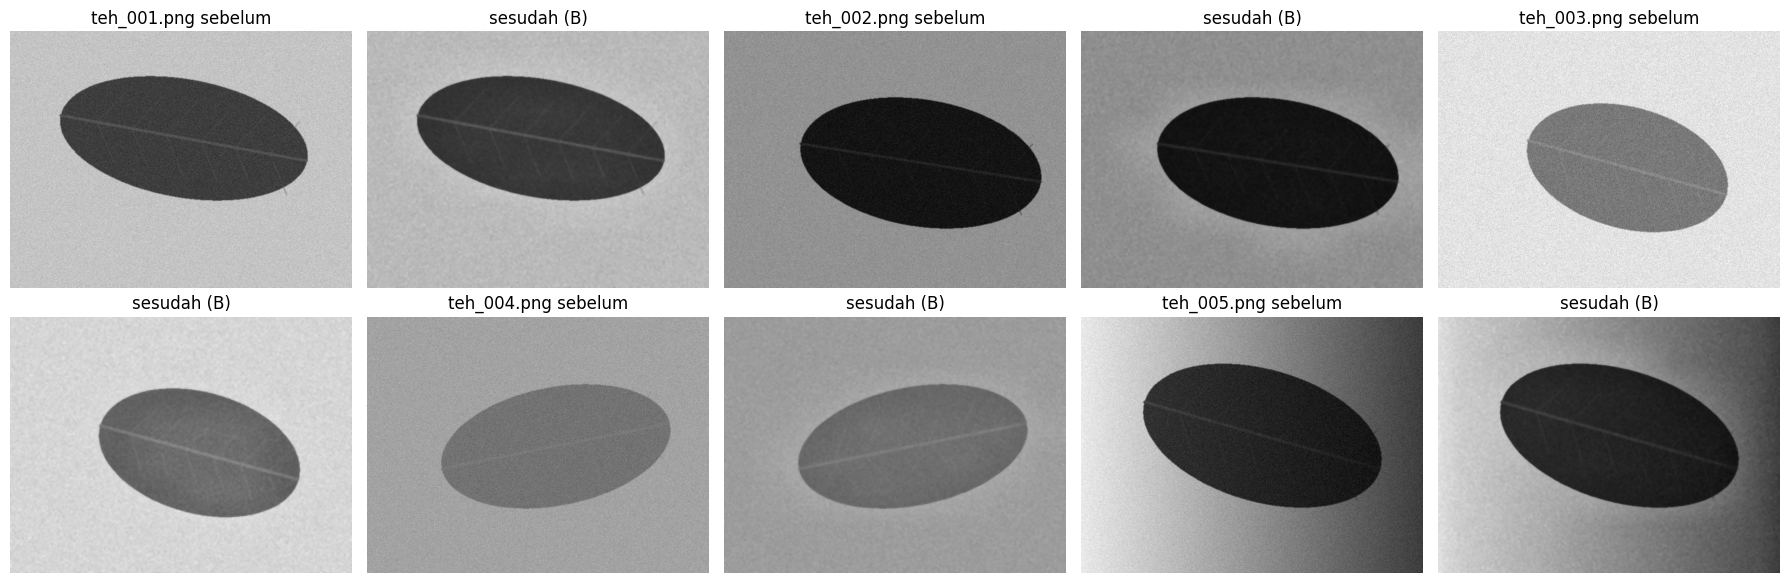

In [142]:
KANAL = 2
label = pd.read_csv("../data/sintetis/label.csv")
kand = {"B": {"clahe_clip": 1.0, "penapis": "median", "kernel": 5},
        "C": {"clahe_clip": 0,   "penapis": "median", "kernel": 5}}

for nk, prm in kand.items():
    baris = []
    for i in range(1, 21):
        nm = f"teh_{i:03d}.png"
        im = baca(f"../data/sintetis/citra/{nm}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
        o = pp(im, prm)
        m_d2 = cv2.resize(m_d, (o.shape[1], o.shape[0]), interpolation=cv2.INTER_NEAREST)
        kond = label.loc[label.nama_file == nm, "kondisi_cahaya"].iloc[0]
        baris.append([kond, im[:, :, KANAL][m_d > 0].std(), o[:, :, KANAL][m_d2 > 0].std()])
    t = (pd.DataFrame(baris, columns=["kondisi", "sd_sebelum", "sd_sesudah"])
         .groupby("kondisi").mean().round(2))
    print("\nKonfigurasi", nk); print(t)
    t.to_csv(f"../hasil/b5_uji_sehat_{nk}.csv")

# panel sebelum-sesudah (konfigurasi B), satu citra sehat per kondisi
daftar, judul = [], []
for nm in ["teh_001.png", "teh_002.png", "teh_003.png", "teh_004.png", "teh_005.png"]:
    im = baca(f"../data/sintetis/citra/{nm}")
    daftar += [im[:, :, KANAL], pp(im, kand["B"])[:, :, KANAL]]
    judul += [f"{nm} sebelum", "sesudah (B)"]
tampil(daftar, judul, baris=2, ukuran=(18, 6))
plt.savefig("../hasil/b5_panel_sehat.png"); plt.show()

In [143]:
param = {"gamma": 1.0, "clahe_clip": 1.0, "penapis": "median", "kernel": 5}
simpan_param(param, "../hasil/param_praproses.json")
print(open("../hasil/param_praproses.json").read())

{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 1.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 5,
  "sigma": 1.0,
  "tajam_k": 0.0
}


In [144]:
KANAL = 2
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    o = pp(im, param)
    baris.append([d.kondisi_cahaya, kontras_bercak(im[:, :, KANAL], m_d, m_b),
                  kontras_bercak(o[:, :, KANAL], m_d, m_b)])
t12 = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"]).groupby("kondisi").mean().round(2)
t12["perubahan_%"] = ((t12.KB_sesudah / t12.KB_sebelum - 1) * 100).round(1)
print(t12); t12.to_csv("../hasil/b5_evaluasi.csv")

                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
bayangan              5.05        8.65         71.3
gelap                 9.92       19.55         97.1
kontras_rendah        3.72        7.30         96.2
normal                8.93       14.13         58.2
terang                6.54        8.75         33.8


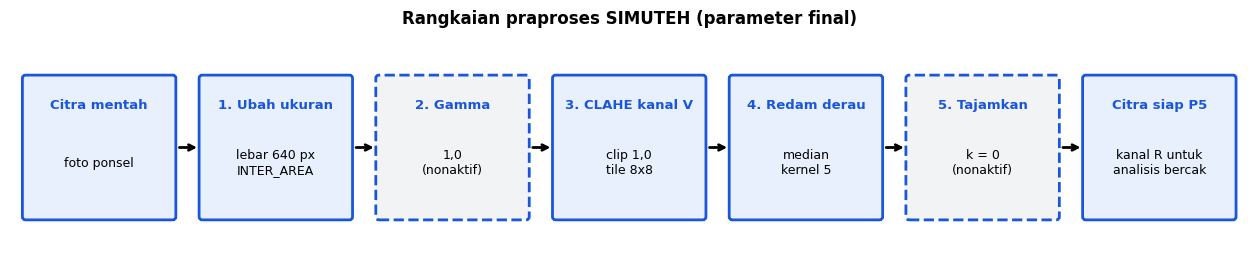

In [145]:
from matplotlib.patches import FancyBboxPatch
langkah = [("Citra mentah", "foto ponsel"),
           ("1. Ubah ukuran", "lebar 640 px\nINTER_AREA"),
           ("2. Gamma", "1,0\n(nonaktif)"),
           ("3. CLAHE kanal V", "clip 1,0\ntile 8x8"),
           ("4. Redam derau", "median\nkernel 5"),
           ("5. Tajamkan", "k = 0\n(nonaktif)"),
           ("Citra siap P5", "kanal R untuk\nanalisis bercak")]
fig, ax = plt.subplots(figsize=(16, 3)); ax.set_xlim(0, 16); ax.set_ylim(0, 3); ax.axis("off")
ax.set_title("Rangkaian praproses SIMUTEH (parameter final)", fontweight="bold")
for i, (j, t) in enumerate(langkah):
    x = 0.2 + i * 2.28
    nonaktif = "nonaktif" in t
    ax.add_patch(FancyBboxPatch((x, 0.6), 1.9, 1.8, boxstyle="round,pad=0.04",
                 fc="#f1f3f4" if nonaktif else "#e8f0fe", ec="#1a56db", lw=2,
                 ls="--" if nonaktif else "-"))
    ax.text(x + 0.95, 2.0, j, ha="center", fontsize=9.5, fontweight="bold", color="#1a56db")
    ax.text(x + 0.95, 1.3, t, ha="center", va="center", fontsize=9)
    if i < len(langkah) - 1:
        ax.annotate("", xy=(x + 2.25, 1.5), xytext=(x + 1.95, 1.5), arrowprops=dict(arrowstyle="->", lw=2))
plt.savefig("../hasil/b5_diagram_praproses.png", dpi=150, bbox_inches="tight"); plt.show()